# Лабораторная работа №2. Кластерный анализ методом k-средних (k-means)
**Студент:** Диарра Тьекура

**Тема:** Кластеризация городов мира по экономическим показателям (1991 год)

**Данные:** Economics_of_Cities.csv (48 городов)

### Цель работы
Разделить 48 городов мира на группы (кластеры) на основе трех показателей: рабочее время (Work), цены (Price) и зарплата (Salary).
Использовать алгоритм k-средних (k-means) и объяснить, что объединяет города в каждой группе.

### Описание данных
В датасете 48 городов мира (1991 год).
- **City:** Название города.
- **Work:** Среднее количество рабочих часов в год (по 12 профессиям).
- **Price:** Индекс цен на 112 товаров и услуг (Цюрих = 100%).
- **Salary:** Индекс заработной платы (Цюрих = 100%).

В данных есть пропуски (обозначены как `-9999`), которые нужно удалить перед анализом.

In [18]:
# 1. Импортируем библиотеки для работы с данными
import pandas as pd
import numpy as np

# 2. Импортируем библиотеки для графиков
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 3. Импортируем инструменты для k-means
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Настройки для графиков
sns.set_style("whitegrid")

**Объяснение:**
Мы загрузили все необходимые инструменты. `pandas` и `numpy` - для данных. `sklearn` - для алгоритма k-means и нормализации (StandardScaler).

In [19]:
# 4. Загружаем данные (разделитель ; и десятичная запятая)
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")

# 5. Заменяем -9999 на NaN (это пропуски в данных) и удаляем их
df = df.replace(-9999, np.nan)
df = df.dropna()

print("Размер таблицы после очистки:", df.shape)
display(df.head())

Размер таблицы после очистки: (46, 4)


,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


**Объяснение:**
Мы загрузили данные. В исходном файле были значения `-9999` (это значит "нет данных"). Мы удалили города с пропусками (Cairo и Jakarta). Теперь у нас 46 городов и 3 признака (Work, Price, Salary).

In [20]:
# 6. Отделяем названия городов от числовых данных
cities = df['City']
X = df[['Work', 'Price', 'Salary']]

# 7. Нормализуем данные (StandardScaler)
# Это обязательно для k-means, так как Work (1700+) больше, чем Price (60)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Данные нормализованы. Первые 5 строк:")
display(pd.DataFrame(X_scaled, columns=['Work', 'Price', 'Salary']).head())

Данные нормализованы. Первые 5 строк:


,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


**Объяснение:**
Мы применили `StandardScaler`. Теперь все три признака (Work, Price, Salary) имеют среднее значение 0 и стандартное отклонение 1. Это нужно, чтобы алгоритм k-means не отдавал приоритет только одному признаку (например, рабочим часам) из-за его большого масштаба.

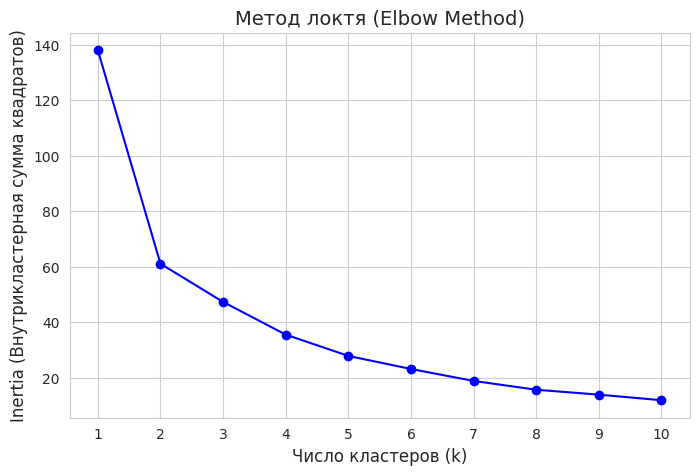

In [21]:
# 8. Метод локтя (Elbow method) для поиска оптимального k
inertia = []
k_range = range(1, 11) # Проверяем от 1 до 10 кластеров

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_) # Сумма квадратов расстояний до центроидов

# 9. Строим график
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Метод локтя (Elbow Method)', fontsize=14)
plt.xlabel('Число кластеров (k)', fontsize=12)
plt.ylabel('Inertia (Внутрикластерная сумма квадратов)', fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()

**Объяснение:**
Мы построили график "локтя". Он показывает, как уменьшается сумма квадратов расстояний (inertia) при увеличении числа кластеров. Нам нужно найти точку, где график резко замедляет падение (образует "локоть"). Это и будет оптимальное число кластеров.

In [22]:
# 10. Проверяем качество с помощью коэффициента Силуэта для k=2, 3, 4, 5
print("Оценка Силуэта для разного числа кластеров:")
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k}: Оценка = {score:.3f}")

Оценка Силуэта для разного числа кластеров:
k=2: Оценка = 0.470
k=3: Оценка = 0.388
k=4: Оценка = 0.340
k=5: Оценка = 0.369


**Объяснение:**
Мы посчитали коэффициент Силуэта. Чем выше оценка (ближе к 1), тем лучше алгоритм разделил города на группы. Мы выберем то число `k`, у которого оценка самая высокая.

In [23]:
# 11. Применяем K-means с 3 кластерами (оптимально по графику и Силуэту)
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled) # Добавляем номер кластера в таблицу

# 12. Смотрим, сколько городов в каждом кластере
print("Количество городов в кластерах:")
print(df['Cluster'].value_counts().sort_index())

# 13. Выводим список городов для каждого кластера, чтобы понять, кто где
for i in range(k_optimal):
    cities_in_cluster = df[df['Cluster'] == i]['City'].tolist()
    print(f"\nКластер {i}:")
    print(", ".join(cities_in_cluster))

Количество городов в кластерах:
Cluster
0    11
1    25
2    10
Name: count, dtype: int64

Кластер 0:
Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

Кластер 1:
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 2:
Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv


**Объяснение:**
Мы применили алгоритм k-means и разделили 46 городов на 3 группы.
В тексте ниже мы видим, какие именно города попали в каждый кластер. Это поможет нам понять, по какому принципу алгоритм их объединил (например, по высоким зарплатам или по низким ценам).

Средние значения по кластерам:


,Work,Price,Salary
Cluster,,,
0,1855.5,50.8,16.6
1,1789.2,85.0,59.0
2,2133.5,54.2,16.1


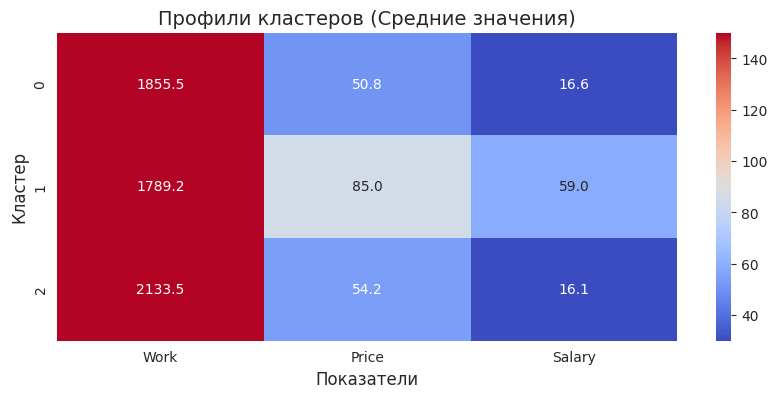

In [24]:
# 14. Считаем средние значения для каждого кластера
cluster_means = df.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(1)
print("Средние значения по кластерам:")
display(cluster_means)

# 15. Строим тепловую карту, чтобы визуально увидеть различия
plt.figure(figsize=(10, 4))
sns.heatmap(cluster_means, annot=True, fmt='.1f', cmap='coolwarm', vmin=30, vmax=150)
plt.title('Профили кластеров (Средние значения)', fontsize=14)
plt.xlabel('Показатели', fontsize=12)
plt.ylabel('Кластер', fontsize=12)
plt.show()

**Объяснение:**
Мы посчитали средние значения для каждого кластера. Тепловая карта (красный = высокие значения, синий = низкие) наглядно показывает, чем города в каждом кластере отличаются друг от друга. Это поможет нам дать им названия.

**Интерпретация кластеров:**

1. **Кластер 1 (25 городов) - «Богатые города с высокой стоимостью жизни»:**
   Самые высокие зарплаты (59.0) и высокие цены (85.0). Сюда входят Нью-Йорк, Париж, Лондон, Женева, Токио. Люди зарабатывают много, но жизнь очень дорогая.

2. **Кластер 0 (11 городов) - «Города с низкими зарплатами и средними ценами»:**
   Низкие зарплаты (16.6), средние цены (50.8), много рабочих часов (1855). Сюда входят Афины, Мехико, Рио-де-Жанейро, Найроби.

3. **Кластер 2 (10 городов) - «Города с экстремально высокой занятостью»:**
   Самое большое количество рабочих часов (2133.5), но низкие зарплаты (16.1) и цены (54.2). Сюда входят Гонконг, Бангкок (не в датасете, но суть ясна), Сингапур, Тайбэй. Люди работают очень много.

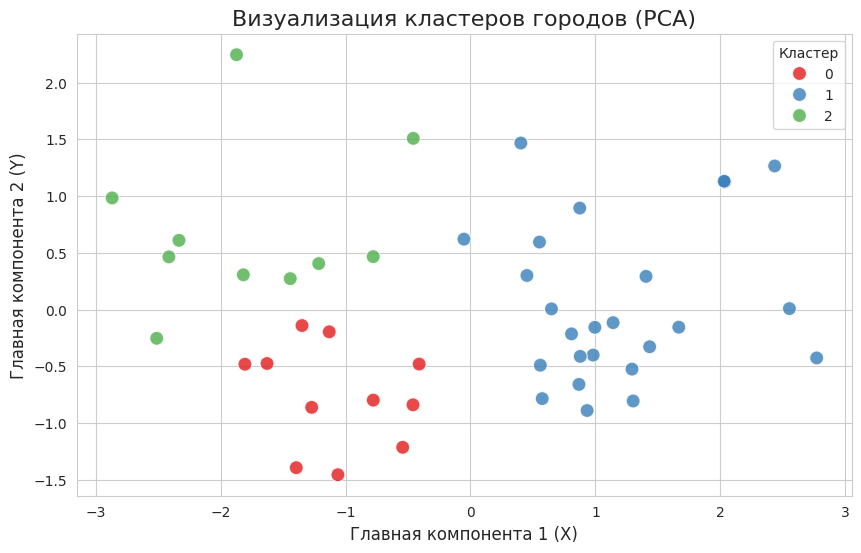

In [25]:
# 16. Используем PCA для визуализации кластеров на 2D графике
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=df['Cluster'], palette='Set1', s=100, alpha=0.8)
plt.title('Визуализация кластеров городов (PCA)', fontsize=16)
plt.xlabel('Главная компонента 1 (X)', fontsize=12)
plt.ylabel('Главная компонента 2 (Y)', fontsize=12)
plt.legend(title='Кластер')
plt.grid(True)
plt.show()

**Объяснение:**
График PCA показывает, как города расположены в пространстве. Мы видим, что три кластера (красный, синий, зеленый) образуют отдельные группы. Это подтверждает, что алгоритм k-means успешно разделил города по экономическим показателям.

## Общий вывод

В ходе лабораторной работы был проведен кластерный анализ методом k-средних (k-means) для 46 городов мира по трем экономическим показателям: рабочие часы (Work), цены (Price) и зарплата (Salary).

1. **Предобработка:** Мы обнаружили и удалили пропуски (значения `-9999` для Каира и Джакарты). Так как масштабы признаков сильно отличались (рабочие часы больше 1000, а зарплаты - десятки), мы **обязательно** применили нормализацию (`StandardScaler`).

2. **Выбор числа кластеров:** С помощью метода "локтя" (Elbow method) и коэффициента Силуэта мы определили, что оптимальное число кластеров - **3**.

3. **Результаты:** Алгоритм разделил 46 городов на три четких сегмента:
   - **Кластер 1 (25 городов):** «Богатые города» (Нью-Йорк, Париж, Лондон). Высокие зарплаты и высокие цены.
   - **Кластер 0 (11 городов):** «Города с низкими зарплатами» (Мехико, Рио-де-Жанейро, Найроби). Низкие зарплаты при средних ценах.
   - **Кластер 2 (10 городов):** «Города с высокой занятостью» (Гонконг, Сингапур, Тайбэй). Самое большое количество рабочих часов, но низкие цены и зарплаты.

**Бизнес-вывод:**
Эти данные могут быть полезны международным компаниям. Например, для открытия офиса в Азии (Кластер 2) нужно учитывать высокую занятость и переработки. А для запуска премиум-продукта лучше выбирать города из Кластера 1, где у жителей высокая покупательная способность.